# What SF throws out vs. what it resells

Three DataSF sources, as close as the portal gets to garage sales and thrifting
(there's no dataset of yard sales, flea markets, or online resale):

- **311 reports of dumped furniture & mattresses** — [311 Cases](https://data.sf.gov/d/vw6y-z8j6)
  (`vw6y-z8j6`), Street and Sidewalk Cleaning → `garbage_and_debris`, filtered server-side to
  `service_details` = furniture / mattress.
- **Registered used-goods businesses** — [Registered Business Locations](https://data.sf.gov/d/g8m3-pdis)
  (`g8m3-pdis`), open locations with a used-merchandise NAICS code or a resale-sounding name.
- **Street vendors** — [Street Vending Permits](https://data.sf.gov/d/34ws-kyf6) (`34ws-kyf6`),
  active permits with free-text descriptions of what's sold.

Caveats up front:

- **311 only tags furniture/mattress since 2024-06-13**, so there's ~2⅓ years of history, and
  311 counts *reports*, not items: neighborhoods with more people walking by (and more people
  who use the 311 app) report more.
- **NAICS codes are self-reported** and the name match is loose; section 3 cleans it by hand.
- Counts by neighborhood aren't normalized for population yet (no population data in the
  registry) — treat them as volume, not rate.

In [1]:
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from shapely.geometry import box

from sfdata import fetch

# Reference palette (light mode): categorical slots 1-2, text inks, grid.
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, SECONDARY, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRID, "axes.labelcolor": SECONDARY,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
})
VIEW = dict(xlim=(-122.525, -122.35), ylim=(37.70, 37.84))  # crops D4's Farallon polygon
view_box = box(VIEW["xlim"][0], VIEW["ylim"][0], VIEW["xlim"][1], VIEW["ylim"][1])

dumped = fetch.load("dumped_furniture_311")
dumped = dumped[dumped["source"] != "Test"].copy()
dumped["requested"] = pd.to_datetime(dumped["requested_datetime"])
dumped["closed"] = pd.to_datetime(dumped["closed_date"])
# Status notes mix "Case Resolved" / "case_resolved" spellings; normalize.
dumped["outcome"] = (
    dumped["status_notes"].fillna("").str.lower().str.replace("_", " ")
    .str.strip(" -").str.split(" - ").str[0].replace("", "(no note)")
)
print(f"{len(dumped):,} reports, {dumped.requested.min():%Y-%m-%d} to {dumped.requested.max():%Y-%m-%d}")
dumped["service_details"].value_counts()

108,352 reports, 2024-06-13 to 2026-10-28


service_details
furniture    81056
mattress     27296
Name: count, dtype: int64

## 1. Dumped furniture over time

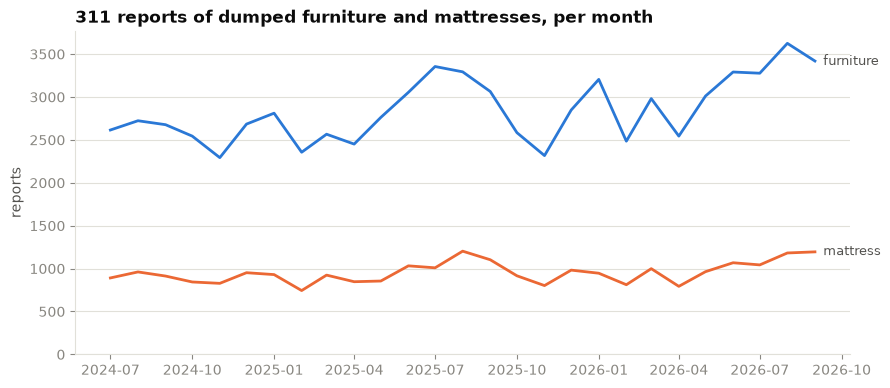

,Jun–Sep 2025,Jun–Sep 2026,change
service_details,,,
furniture,12766,13612,+7%
mattress,4347,4488,+3%


In [2]:
monthly = (
    dumped.groupby([dumped.requested.dt.to_period("M"), "service_details"]).size()
    .unstack().drop(index=[pd.Period("2024-06", "M")])  # tagging began mid-June
)
# Drop the current, partial month.
monthly = monthly[monthly.index < pd.Timestamp.now().to_period("M")]

fig, ax = plt.subplots(figsize=(10, 4.2))
x = monthly.index.to_timestamp()
for col, color in [("furniture", BLUE), ("mattress", ORANGE)]:
    ax.plot(x, monthly[col], color=color, lw=2)
    ax.annotate(col, (x[-1], monthly[col].iloc[-1]), xytext=(6, 0),
                textcoords="offset points", va="center", color=SECONDARY, fontsize=9)
ax.set_ylim(0, None)
ax.grid(axis="y", color=GRID, lw=0.8)
ax.set_title("311 reports of dumped furniture and mattresses, per month")
ax.set_ylabel("reports")
plt.show()

summer = lambda y: monthly.loc[f"{y}-06":f"{y}-09"].sum()
yoy = pd.DataFrame({"Jun–Sep 2025": summer(2025), "Jun–Sep 2026": summer(2026)})
yoy["change"] = (yoy.iloc[:, 1] / yoy.iloc[:, 0] - 1).map("{:+.0%}".format)
yoy

## 2. Moving day: the turn of the month

SF leases turn over at month-end, so if dumping is driven by moves, reports should bunch
around the 1st. Day 31 only exists in some months (and 29–30 not in February), so this is
reports **per occurrence of that calendar day**, relative to the average day.

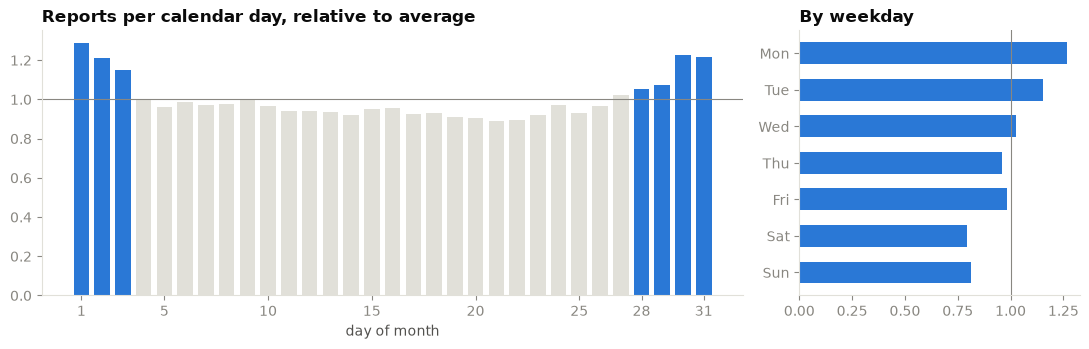

28th–3rd: 1.17× an average day; the 1st alone: 1.29×


In [3]:
days = pd.date_range(dumped.requested.min().normalize(), dumped.requested.max().normalize())
occurrences = pd.Series(days.day).value_counts().sort_index()
per_day = dumped.requested.dt.day.value_counts().sort_index() / occurrences
rel = per_day / per_day.mean()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [3, 1.2]})
ax = axes[0]
ax.bar(rel.index, rel.values, color=[BLUE if (d >= 28 or d <= 3) else GRID for d in rel.index],
       width=0.75)
ax.axhline(1, color=MUTED, lw=0.8)
ax.set_xticks([1, 5, 10, 15, 20, 25, 28, 31])
ax.set_title("Reports per calendar day, relative to average")
ax.set_xlabel("day of month")

dow = dumped.requested.dt.day_name().value_counts()
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
dow = dow[order] / dow.mean()
ax = axes[1]
ax.barh([d[:3] for d in order][::-1], dow.values[::-1], color=BLUE, height=0.6)
ax.axvline(1, color=MUTED, lw=0.8)
ax.set_title("By weekday")
plt.tight_layout()
plt.show()

print(f"28th–3rd: {rel[(rel.index >= 28) | (rel.index <= 3)].mean():.2f}× an average day; "
      f"the 1st alone: {rel[1]:.2f}×")

## 3. What happens to it

Recology closes most reports within a couple of hours. **"Unable to locate"** is the
interesting outcome here: the item was gone by the time the crew arrived. Someone may have
taken it (informal curbside reuse), but it could also be a vague location or a busy street.

median time to close: 1.7 h; 90th percentile: 15.8 h


outcome
case resolved                     83.9%
(no note)                          8.1%
unable to locate                   5.4%
case is a duplicate                2.1%
insufficient information provi     0.2%
case is invalid                    0.1%
administrative closure             0.1%
new                                0.0%
Name: share of reports, dtype: str

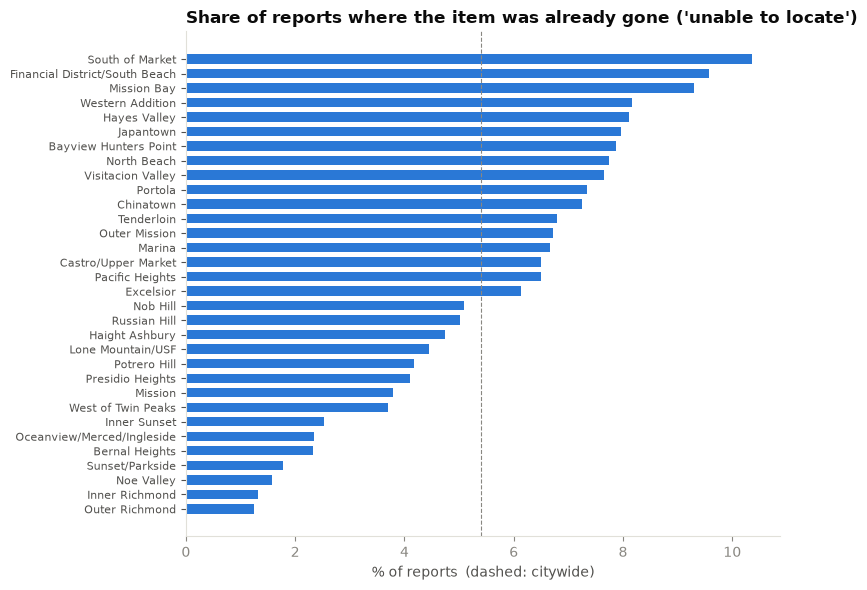

In [4]:
hours = (dumped.closed - dumped.requested).dt.total_seconds() / 3600
print(f"median time to close: {hours.median():.1f} h; 90th percentile: {hours.quantile(.9):.1f} h")

top_outcomes = dumped["outcome"].value_counts()
display((top_outcomes.head(8) / len(dumped)).map("{:.1%}".format).rename("share of reports"))

by_hood = dumped.groupby("analysis_neighborhood").agg(
    reports=("service_request_id", "size"),
    gone_on_arrival=("outcome", lambda s: (s == "unable to locate").mean()),
)
by_hood = by_hood[by_hood.reports >= 500]
fig, ax = plt.subplots(figsize=(8, 6))
s = by_hood.gone_on_arrival.sort_values()
ax.barh(s.index, s.values * 100, color=BLUE, height=0.65)
ax.axvline((dumped.outcome == "unable to locate").mean() * 100, color=MUTED, lw=0.8, ls="--")
ax.set_title("Share of reports where the item was already gone ('unable to locate')")
ax.set_xlabel("% of reports  (dashed: citywide)")
ax.tick_params(axis="y", labelsize=8, colors=SECONDARY)
plt.tight_layout()
plt.show()

## 4. Used-goods businesses

In [5]:
biz = fetch.load("used_goods_businesses")
biz["naics"] = biz["self_reported_naics_code"].astype("Int64").astype(str)
biz["rule"] = np.where(biz["naics"].isin(["459510", "453310"]), "naics", "name")

# Name matches that aren't resellers (reviewed by hand, 2026-10-30): "thrifty" car rental,
# a coach named Goodwill, wine bars and contractors named Vintage, Salvation Army housing
# and admin sites, banks matching "antique", a restaurant called The Pawn Shop, ...
NOT_RESALE = re.compile(
    r"car rental|coach|wine|elevator|contractor|construction|transatlantique|cafe|hotel|"
    r"urban development|fair trading|pawnee|vintage spoon|fog city resale|hope house|"
    r"harbor house|silvercrest|arc admin|mcfee|^the pawn shop$",
    re.I,
)
excluded = biz[(biz.rule == "name") & biz.dba_name.str.contains(NOT_RESALE)]
shops = biz.drop(excluded.index)
shops = shops[shops.neighborhoods_analysis_boundaries.notna()]  # drops mailing-only / out-of-SF

# Coordinates come as WKT "POINT (lon lat)".
xy = shops["location"].str.extract(r"POINT \(([-\d.]+) ([-\d.]+)\)").astype(float)
shops["lon"], shops["lat"] = xy[0], xy[1]

print(f"{len(biz)} matched, {len(excluded)} excluded as not resale, "
      f"{len(biz) - len(excluded) - len(shops)} outside SF/no location -> {len(shops)} shops")
display(shops.rule.value_counts())
shops.neighborhoods_analysis_boundaries.value_counts().head(10)

330 matched, 24 excluded as not resale, 15 outside SF/no location -> 291 shops


rule
naics    195
name      96
Name: count, dtype: int64

neighborhoods_analysis_boundaries
Mission                           38
Haight Ashbury                    25
South of Market                   15
Bayview Hunters Point             15
Outer Richmond                    14
Bernal Heights                    12
Financial District/South Beach    12
Sunset/Parkside                   11
Castro/Upper Market               10
Presidio Heights                  10
Name: count, dtype: int64

## 5. Street vendors selling second-hand goods

**This is a snapshot, not a history**: only permits that are active or approved right now
(expiring Nov 2026 – Nov 2027); expired permits drop out. The program is small: permit
numbers are sequential per year (24VDR-00177, 25VDR-00161, 26VDR-00115 are the highest
visible), and an Internet Archive copy from Oct 2025 had 172 active permits, so ~150–180 a
year is the real volume. It also only covers **permitted** vendors; informal street vending,
where a lot of used-goods selling happens, isn't here.

Most permits are for new merchandise (jewelry, phone accessories, clothes) or giving away
Lifeline phones; about 40% have no description at all. A keyword pass finds the
second-hand sellers.

In [6]:
vend = fetch.load("street_vending_permits")
desc = vend["describewhatyouwillsell"].fillna("")
SECONDHAND = re.compile(r"\bused\b|second[- ]?hand|2nd hand|antique|vintage|old clothes", re.I)
vend["secondhand"] = desc.str.contains(SECONDHAND)
print(f"{len(vend)} permits; {(desc == '').sum()} with no description; "
      f"{vend.secondhand.sum()} second-hand")
vend.loc[vend.secondhand, ["describewhatyouwillsell", "analysis_neighborhood"]]

152 permits; 60 with no description; 13 second-hand


,describewhatyouwillsell,analysis_neighborhood
0,selling new and used books,South of Market
5,"Second hand clothes, handbags, perfumes, socks...",Outer Mission
8,"I will sell phone chargers (wall and car), cab...",Outer Mission
11,"Used clothes, toys, household supplies, used b...",Mission
15,"Second-hand merchandise, for example articles ...",Mission
16,Second-hand objects and antiques,Mission
18,Electronics and homegood new and used,Mission
41,"Clothing, used goods, vintage wares",Mission
46,2nd hand clothes,Mission
47,second hand clothings and shoes,Mission


## 6. On the map: discarded vs. resold

Neighborhood shading is dumped furniture/mattress reports since June 2024; dots are used-goods
shops and second-hand street vendors.

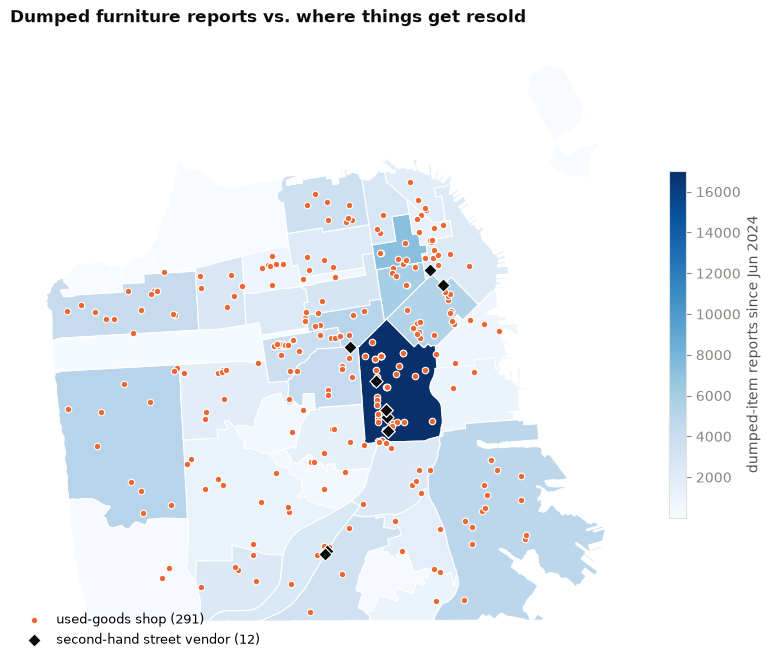

,dumped_reports,used_goods_shops
Mission,17014,38
Nob Hill,7206,6
Tenderloin,5957,6
South of Market,5292,15
Sunset/Parkside,5096,11
Hayes Valley,5080,9
Bayview Hunters Point,4840,15
Castro/Upper Market,4277,10
Outer Richmond,4265,14
Haight Ashbury,3797,25


In [7]:
hoods = fetch.load("analysis_neighborhoods").merge(
    dumped.analysis_neighborhood.value_counts().rename("reports"),
    left_on="nhood", right_index=True, how="left",
)
city = fetch.load("city_boundary")

fig, ax = plt.subplots(figsize=(10, 9))
hoods.plot(ax=ax, column="reports", cmap="Blues", edgecolor="white", linewidth=0.8,
           legend=True, legend_kwds={"shrink": 0.5, "label": "dumped-item reports since Jun 2024"})
ax.scatter(shops.lon, shops.lat, s=22, color=ORANGE, edgecolor="white", lw=0.8,
           label=f"used-goods shop ({len(shops)})", zorder=3)
sv = vend[vend.secondhand & vend.latitude.notna()]
ax.scatter(sv.longitude, sv.latitude, s=46, marker="D", color=INK, edgecolor="white", lw=0.8,
           label=f"second-hand street vendor ({len(sv)})", zorder=4)
ax.set(**VIEW)
ax.set_axis_off()
ax.legend(loc="lower left", frameon=False, fontsize=9)
ax.set_title("Dumped furniture reports vs. where things get resold")
plt.show()

summary = pd.DataFrame({
    "dumped_reports": dumped.analysis_neighborhood.value_counts(),
    "used_goods_shops": shops.neighborhoods_analysis_boundaries.value_counts(),
}).fillna(0).astype(int).sort_values("dumped_reports", ascending=False)
summary.head(12)

## Observations

_Numbers as of the 2026-10-30 pull._

- **Dumping is seasonal and rising.** Reports peak June–September (move-out and student
  season) and the summer of 2026 ran above 2025's.
- **Moving day shows up clearly.** Reports per calendar day run well above average from the
  28th through the 3rd, peaking on the 1st, which is what you'd expect if lease turnover drives
  it. Mondays are the busiest weekday (weekend dumping reported Monday).
- **About 1 in 20 items is gone before the crew arrives** ("unable to locate"), but the
  pattern doesn't read as simple curbside reuse: it's highest downtown (SoMa ~10%, Financial
  District, Mission Bay) and lowest in the Richmond, Sunset, and Noe Valley (1–2%), with the
  Mission below average. Downtown, the report location may be less precise or busier, so crews
  can't find the item. Worth checking against report source and time-to-arrival before reading
  it as reuse.
- **The Mission leads on both counts**: by far the most dumped-item reports (17k, 2.4× the
  next neighborhood) *and* the most used-goods shops (38), plus 7 of the 13 permitted
  second-hand street vendors. Haight Ashbury (25 shops) is the other thrift cluster.
- **Permitted street vending is tiny** (~150 active permits) and says little about informal
  resale.

## Next steps

- Normalize by population/households (ACS by tract → neighborhood via the crosswalk) to turn
  volume into rates.
- Check whether the 2026 rise is real or reflects 311 app adoption (source mix over time).
- 311 `media_url` photos exist for most app reports — could sample a few to sanity-check tags.
- Candidate site page: the month-end chart plus the map.